# Klasifikasi Multi-class: Iris, Wine, dan Penguins

## Sekilas tentang multi-class

Multi-class classification adalah tugas memprediksi **satu kelas dari tiga atau lebih kelas yang mungkin**. Tiap sampel pasti masuk ke tepat satu kelas, dan kelas-kelasnya saling meniadakan. Contohnya di sini: sebuah bunga hanya bisa berjenis setosa, versicolor, atau virginica, tidak bisa dua-duanya sekaligus.

Bedanya dengan kategori lain:
- **Binary**: hanya dua kelas (misalnya selamat atau tidak).
- **Multi-class**: lebih dari dua kelas, tapi tetap satu label per sampel.
- **Multi-label**: satu sampel boleh punya beberapa label sekaligus.

Secara teknis, model multi-class biasanya memakai softmax (probabilitas semua kelas dijumlahkan jadi 1) dengan categorical cross-entropy sebagai loss. Metriknya sebaiknya macro atau weighted F1 plus confusion matrix, bukan hanya accuracy, terutama kalau kelasnya timpang.

In [1]:
import os, io, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

SEED = 42
# Folder tempat semua file zip/CSV berada. Bisa diubah, atau set environment variable DATA_DIR.
DATA_DIR = os.environ.get("DATA_DIR", ".")

def find_zip(n):
    # cocok dengan 'archive (8).zip', 'archive__8_.zip', dst.
    pat = re.compile(rf"archive\D*{n}\D*\.zip$", re.I)
    for f in sorted(os.listdir(DATA_DIR)):
        if pat.search(f):
            return os.path.join(DATA_DIR, f)
    raise FileNotFoundError(f"Zip arsip {n} tidak ditemukan di DATA_DIR={DATA_DIR!r}")

def find_file(test, hint):
    # cari file yang namanya lolos 'test', baik file biasa maupun di dalam zip mana pun di DATA_DIR
    for root, _, files in os.walk(DATA_DIR):
        for f in sorted(files):
            p = os.path.join(root, f)
            if f.lower().endswith(".zip"):
                try:
                    with zipfile.ZipFile(p) as z:
                        for m in z.namelist():
                            if test(os.path.basename(m)):
                                return z.read(m), f"{f} -> {m}"
                except zipfile.BadZipFile:
                    pass
            elif test(f):
                with open(p, "rb") as fh:
                    return fh.read(), p
    raise FileNotFoundError(f"File {hint} tidak ketemu di DATA_DIR={DATA_DIR!r}. Unduh dulu dari Kaggle (lihat link di atas).")

## 1. Memuat data

In [2]:
# --- Iris: dari archive (8).zip ---
with zipfile.ZipFile(find_zip(8)) as z:
    iris = pd.read_csv(z.open("iris.csv"))

# --- Wine: kolom pertama biasanya kelas (1, 2, 3) ---
WINE_COLS = ["class", "Alcohol", "Malic acid", "Ash", "Alcalinity of ash", "Magnesium", "Total phenols",
             "Flavanoids", "Nonflavanoid phenols", "Proanthocyanins", "Color intensity", "Hue",
             "OD280/OD315", "Proline"]

def is_wine(name):
    n = name.lower()
    return "wine" in n and "quality" not in n and n.endswith((".csv", ".data"))

raw, src_wine = find_file(is_wine, "Wine")
wine = pd.read_csv(io.BytesIO(raw))
try:                                   # kalau nama kolom semuanya angka, berarti filenya tidak punya header
    [float(col) for col in wine.columns]
    wine = pd.read_csv(io.BytesIO(raw), header=None, names=WINE_COLS if wine.shape[1] == 14 else None)
except ValueError:
    pass

def find_target(df):
    # kolom numerik dengan tepat 3 nilai di antara 0-3 = kolom kelas
    cands = [col for col in df.columns if pd.api.types.is_numeric_dtype(df[col])
             and df[col].nunique() == 3 and set(df[col].unique()) <= {0, 1, 2, 3}]
    pref = [col for col in cands if re.search(r"class|type|cultivar|wine|target|label", str(col), re.I)]
    return (pref or cands or [df.columns[0]])[0]

wine = wine.rename(columns={find_target(wine): "class"})

# --- Penguins: penguins_size.csv ---
raw, src_peng = find_file(lambda n: n.lower() in ("penguins_size.csv", "penguins.csv"), "penguins_size.csv")
peng = pd.read_csv(io.BytesIO(raw)).replace(".", np.nan)    # ada satu baris dengan sex '.', dianggap kosong

data = {"Iris": (iris, "species"), "Wine": (wine, "class"), "Penguins": (peng, "species")}
print("Wine     dari:", src_wine)
print("Penguins dari:", src_peng)
print({k: v[0].shape for k, v in data.items()})

Wine     dari: archive (7).zip -> Wine.csv
Penguins dari: archive (9).zip -> penguins_size.csv
{'Iris': (150, 5), 'Wine': (178, 14), 'Penguins': (344, 7)}


## 2. Gambaran umum data

In [3]:
rows = []
for k, (df, t) in data.items():
    X = df.drop(columns=t)
    n_num = X.select_dtypes(include="number").shape[1]
    rows.append({"Dataset": k, "Baris": len(df), "Fitur numerik": n_num, "Fitur kategorikal": X.shape[1] - n_num,
                 "Kelas": df[t].nunique(), "Nilai kosong": int(df.isna().sum().sum()),
                 "Baris duplikat": int(df.duplicated().sum())})
pd.DataFrame(rows).set_index("Dataset")

,Baris,Fitur numerik,Fitur kategorikal,Kelas,Nilai kosong,Baris duplikat
Dataset,,,,,,
Iris,150,4,0,3,0,1
Wine,178,13,0,3,0,0
Penguins,344,4,2,3,19,0


Dari tabel ini sudah kelihatan ketiganya beda karakter. Iris kecil dan bersih. Wine punya 13 fitur numerik dengan skala yang sangat beda-beda. Penguins punya fitur campuran (angka dan kategori) dan ada nilai kosong.

## 3. Target dan distribusi kelas

Targetnya `species` (Iris dan Penguins) dan kolom kelas 1-3 (Wine, yang kuberi nama `class`). Kita lihat seberapa seimbang kelasnya.

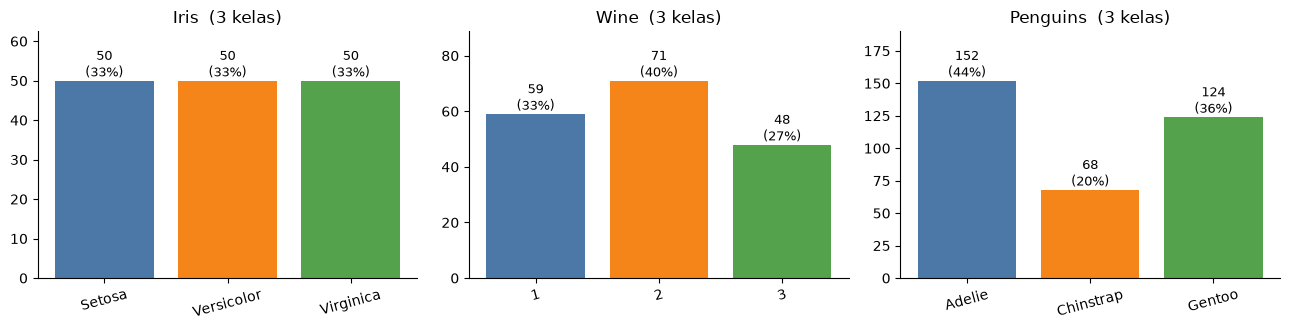

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.4))
for ax, (k, (df, t)) in zip(axs, data.items()):
    vc = df[t].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color=["#4C78A8", "#F58518", "#54A24B"])
    ax.set_title(f"{k}  ({len(vc)} kelas)"); ax.set_ylim(0, vc.max() * 1.25)
    ax.tick_params(axis="x", rotation=15)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v}\n({v/vc.sum():.0%})", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

Iris seimbang sempurna (50:50:50). Wine sedikit timpang (59:71:48). Penguins yang paling timpang: Adelie sekitar 44%, sedangkan Chinstrap hanya sekitar 20%.

## 4. Nilai kosong di Penguins

Penguins satu-satunya yang punya nilai kosong, jadi kita lihat dulu sebarannya. Nanti di model, nilai kosongnya diisi otomatis (median untuk angka, nilai terbanyak untuk kategori) supaya tidak ada baris yang dibuang.

In [5]:
miss = peng.isna().sum()
print("Nilai kosong per kolom:"); print(miss[miss > 0].to_string())
num_cols = peng.select_dtypes(include="number").columns
print("\nBaris yang semua fitur angkanya kosong:", int(peng[num_cols].isna().all(axis=1).sum()))
print("Distribusi sex:", peng["sex"].value_counts(dropna=False).to_dict())

Nilai kosong per kolom:
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  11

Baris yang semua fitur angkanya kosong: 2
Distribusi sex: {'MALE': 168, 'FEMALE': 165, nan: 11}


## 5. Baseline model

Logistic Regression dan Random Forest, 5-fold stratified cross-validation. Fitur numerik distandarkan, fitur kategorikal di-one-hot, dan nilai kosong diisi di dalam pipeline (jadi tidak bocor antar fold).

In [6]:
def make_prep(X, scale=True):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [col for col in X.columns if col not in num]
    steps = [("num", make_pipeline(SimpleImputer(strategy="median"),
                                   StandardScaler() if scale else "passthrough"), num)]
    if cat:
        steps.append(("cat", make_pipeline(SimpleImputer(strategy="most_frequent"),
                                           OneHotEncoder(handle_unknown="ignore")), cat))
    return ColumnTransformer(steps)

def get_models(X, scale=True):
    return {"LogReg": make_pipeline(make_prep(X, scale), LogisticRegression(max_iter=3000)),
            "RandomForest": make_pipeline(make_prep(X, scale), RandomForestClassifier(200, random_state=SEED, n_jobs=-1))}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
out = []
for k, (df, t) in data.items():
    X, y = df.drop(columns=t), df[t]
    for name, m in get_models(X).items():
        r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
        out.append({"Dataset": k, "Model": name, "Majority acc": y.value_counts(normalize=True).max(),
                    "Accuracy": r["test_accuracy"].mean(), "Std acc": r["test_accuracy"].std(),
                    "Macro-F1": r["test_f1_macro"].mean()})
res_mc = pd.DataFrame(out).set_index(["Dataset", "Model"])
res_mc.round(3)

Majority acc  Accuracy  Std acc  Macro-F1
Dataset  Model                                                  
Iris     LogReg               0.333     0.953    0.045     0.953
         RandomForest         0.333     0.960    0.039     0.960
Wine     LogReg               0.399     0.983    0.014     0.983
         RandomForest         0.399     0.977    0.021     0.978
Penguins LogReg               0.442     0.988    0.011     0.987
         RandomForest         0.442     0.991    0.007     0.990

Ketiganya mudah buat model apa pun: akurasi sudah di atas 0,95, jauh di atas tebakan kelas mayoritas. Jadi angka akurasi di sini tidak terlalu berguna untuk membedakan dataset. Yang lebih menarik adalah di mana modelnya masih salah, dan itu kelihatan di confusion matrix berikut.

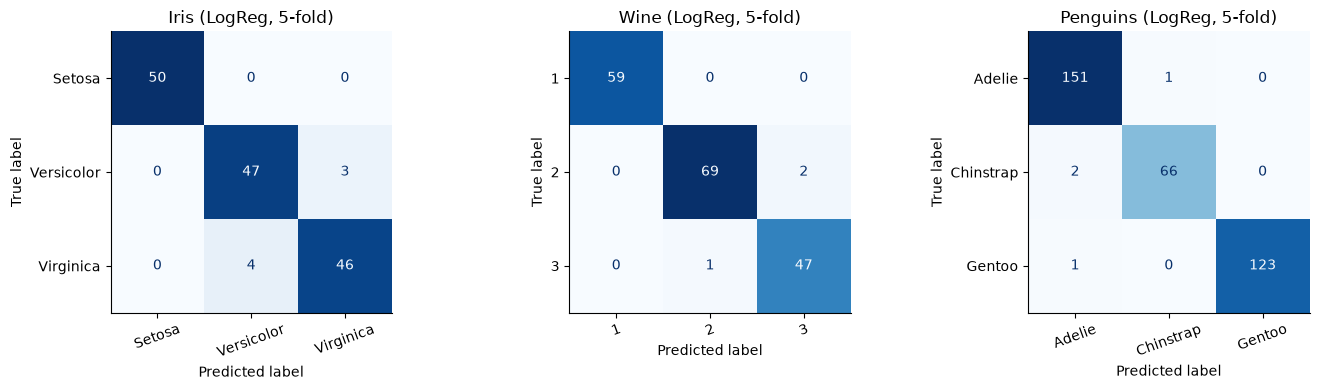

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (k, (df, t)) in zip(axs, data.items()):
    X, y = df.drop(columns=t), df[t]
    pred = cross_val_predict(get_models(X)["LogReg"], X, y, cv=cv)
    labels = sorted(y.unique())
    ConfusionMatrixDisplay(confusion_matrix(y, pred, labels=labels),
                           display_labels=[str(l) for l in labels]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{k} (LogReg, 5-fold)"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

Di Iris, kesalahan terjadi antara versicolor dan virginica, sedangkan setosa selalu benar. Di Wine dan Penguins hampir semuanya benar.

### Efek scaling di Wine

Wine punya fitur dengan skala yang jauh berbeda (Proline ribuan, Hue di bawah 2). Kita lihat apakah standardisasi benar-benar membantu Logistic Regression.

In [8]:
Xw, yw = wine.drop(columns="class"), wine["class"]
hasil = {}
for scale in (True, False):
    r = cross_validate(get_models(Xw, scale)["LogReg"], Xw, yw, cv=cv, scoring="accuracy")
    hasil["Dengan scaling" if scale else "Tanpa scaling"] = r["test_score"].mean()
pd.Series(hasil, name="Accuracy LogReg (Wine)").round(3).to_frame()

,Accuracy LogReg (Wine)
Dengan scaling,0.983
Tanpa scaling,0.966


Selisihnya kecil tapi ada: tanpa scaling, Logistic Regression sedikit lebih buruk di Wine. Efeknya baru benar-benar terasa di data yang lebih sulit.

## 6. Apakah benar-benar multi-class?

In [9]:
verif = pd.DataFrame({
    k: {"Kolom target": t, "Jumlah kelas": df[t].nunique(), "Label per sampel": 1,
        "Target ada yang kosong": int(df[t].isna().sum()),
        "Lolos (>2 kelas, 1 label/sampel)": df[t].nunique() > 2 and df[t].isna().sum() == 0}
    for k, (df, t) in data.items()}).T
verif

,Kolom target,Jumlah kelas,Label per sampel,Target ada yang kosong,"Lolos (>2 kelas, 1 label/sampel)"
Iris,species,3,1,0,True
Wine,class,3,1,0,True
Penguins,species,3,1,0,True


Ketiganya lolos: satu kolom target, tiga kelas yang saling eksklusif, dan tidak ada target yang kosong.

| Dataset | Skor | Alasan |
|---|---|---|
| Iris | 5 | Multi-class klasik: tiga kelas eksklusif dan seimbang sempurna. Paling bersih, tapi juga paling "buku teks". |
| Wine | 5 | Tiga kelas eksklusif, sedikit timpang, 13 fitur numerik. Struktur target murni multi-class. |
| Penguins | 5 | Tiga kelas eksklusif dengan ketimpangan yang lebih nyata, fitur campuran numerik dan kategorikal, serta ada nilai kosong. Paling mendekati masalah multi-class di dunia nyata. |

## 7. Perbandingan ringkas

In [10]:
SKOR = {"Iris": 5, "Wine": 5, "Penguins": 5}
summary = pd.DataFrame({
    "Sampel": {k: len(v[0]) for k, v in data.items()},
    "Fitur numerik": {k: v[0].drop(columns=v[1]).select_dtypes(include="number").shape[1] for k, v in data.items()},
    "Fitur kategorikal": {k: v[0].drop(columns=v[1]).shape[1] - v[0].drop(columns=v[1]).select_dtypes(include="number").shape[1] for k, v in data.items()},
    "Kelas": {k: v[0][v[1]].nunique() for k, v in data.items()},
    "Imbalance (max/min)": {k: round(v[0][v[1]].value_counts().max() / v[0][v[1]].value_counts().min(), 2) for k, v in data.items()},
    "Nilai kosong": {k: int(v[0].isna().sum().sum()) for k, v in data.items()},
    "Accuracy (LogReg)": {k: round(res_mc.loc[(k, "LogReg"), "Accuracy"], 3) for k in data},
    "Macro-F1 (LogReg)": {k: round(res_mc.loc[(k, "LogReg"), "Macro-F1"], 3) for k in data},
    "Skor kesesuaian": SKOR,
})
summary

,Sampel,Fitur numerik,Fitur kategorikal,Kelas,Imbalance (max/min),Nilai kosong,Accuracy (LogReg),Macro-F1 (LogReg),Skor kesesuaian
Iris,150,4,0,3,1.00,0,0.953,0.953,5
Wine,178,13,0,3,1.48,0,0.983,0.983,5
Penguins,344,4,2,3,2.24,19,0.988,0.987,5


## 8. Kesimpulan

Dari sisi definisi, ketiganya sama-sama murni multi-class, jadi skor strukturnya sama. Pembedanya ada di hal lain.

Kalau harus memilih satu yang paling mewakili kategori ini, aku pilih **Penguins**. Kelasnya timpang secara realistis, fiturnya campuran angka dan kategori, dan ada nilai kosong, jadi paling mirip dengan masalah multi-class sungguhan. Iris tetap yang paling klasik dan bersih (cocok buat demo), sedangkan Wine unggul di jumlah fitur numerik dan efek skala fitur.

Dibanding versi sebelumnya (tiga Iris), perbandingannya sekarang jauh lebih bermakna: ukuran data, jenis fitur, tingkat ketimpangan, dan nilai kosongnya beda-beda. Satu catatan jujur: ketiganya tetap mudah (akurasi di atas 0,95), jadi dataset-dataset ini lebih cocok untuk memahami karakter data daripada menguji kemampuan model yang sebenarnya.

Soal pemodelan: neural network untuk multi-class biasanya memakai softmax dengan categorical cross-entropy, dan metrik yang cocok adalah macro atau weighted F1 plus confusion matrix. Pada data yang timpang seperti Penguins, macro-F1 lebih jujur daripada accuracy.